<a href="https://colab.research.google.com/github/karlaguio/Assignment-1-WEB102/blob/main/IL18106_assignement2_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Can logic-gated CAR-T cells improve antigen coverage in glioblastoma?

## 1. Background and research question
In my first assignment, I learned about how logic-gated CAR-T cells could address antigen heterogeneity and off-tumor toxicity in glioblastoma (GBM). For this assignment, I wanted to move from reading about those designs to asking what real single-cell expression data can tell us about their potential. In particular, Choe et al. (2021) used an EGFRvIII-responsive synNotch receptor to induce a CAR recognizing EphA2 or IL13Rα2. I was interested in if expression of these two killing targets actually overlaps across cells.

**Question:** How much additional RNA-based target coverage does combining EPHA2 and IL13RA2 provide compared with either target alone, how does this differ between malignant and nonmalignant cells, and how does it vary across samples and expression thresholds?

**Hypothesis:** An OR rule will cover more cells than either individual target, but the magnitude of the improvement will depend on how much the two transcripts overlap. An AND rule will cover fewer cells. These ordering relationships follow mathematically from the rules; the empirical question is the magnitude and variability of the differences.

I also include EGFR and ERBB2 as exploratory comparators. This is not an experimental measurement of CAR-mediated killing or safety.

### A short guide to the biology
Before comparing the gates, I want to clarify what a T cell actually needs to recognize and respond to a target. A conventional T-cell receptor (TCR) binds a peptide presented by MHC. Its associated CD3 chains transmit an activation signal: Lck phosphorylates ITAMs (signaling motifs), which recruit ZAP-70 and initiate downstream pathways. CD28 binding to CD80/CD86 provides a second, costimulatory signal that supports activation, metabolism and survival. Together these signals promote transcriptional responses involving NFAT, AP-1 and NF-κB.

A CAR can recognize a surface antigen directly, without peptide–MHC recognition. A typical second-generation CAR combines an antigen-binding region with CD3ζ (activation) and either CD28 or 4-1BB (costimulation). The Choe et al. killing CAR specifically uses 4-1BB and CD3ζ; its synNotch priming receptor instead induces transcription of that CAR. These are different types of signaling, not interchangeable receptors. [Choe et al., 2021, Methods](https://pmc.ncbi.nlm.nih.gov/articles/PMC8362330/).

The diagram is a simplified overview of it. The downstream pathways overlap and are not only controlled by one receptor.

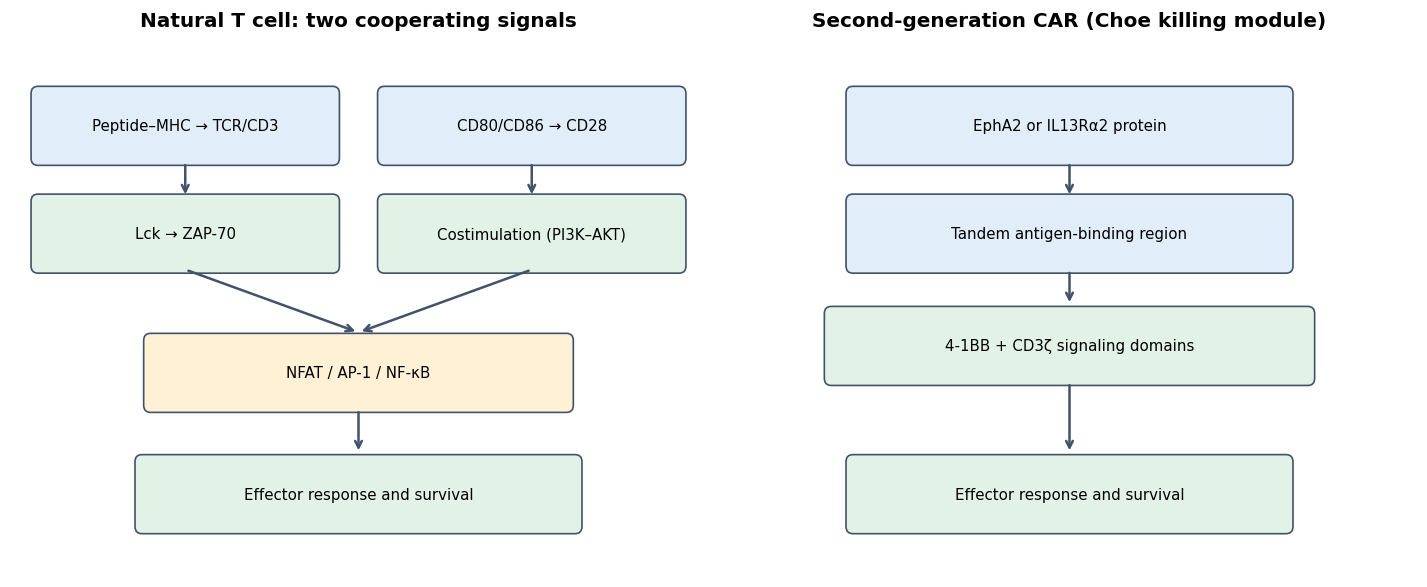

In [ ]:
# this is a conceptual diagram of natural T-cell signaling versus engineered CAR signaling
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def node(ax, x, y, text, color, w=3.4, h=.72):
    ax.add_patch(FancyBboxPatch((x-w/2,y-h/2),w,h,boxstyle='round,pad=0.08',fc=color,ec='#40536a'))
    ax.text(x,y,text,ha='center',va='center',fontsize=9)

def arrow(ax,x,y,x2,y2):
    ax.annotate('',(x2,y2),(x,y),arrowprops={'arrowstyle':'->','color':'#40536a','lw':1.5})

fig, axes = plt.subplots(1,2,figsize=(12,5))
for ax in axes:
    ax.set(xlim=(0,8),ylim=(0,6)); ax.axis('off')
ax=axes[0]; ax.set_title('Natural T cell: two cooperating signals',weight='bold')
for x,top,mid in [(2,'Peptide–MHC → TCR/CD3','Lck → ZAP-70'),(6,'CD80/CD86 → CD28','Costimulation (PI3K–AKT)')]:
    node(ax,x,5,top,'#e1edf9'); node(ax,x,3.8,mid,'#e3f2e7'); arrow(ax,x,4.6,x,4.2); arrow(ax,x,3.4,4,2.7)
node(ax,4,2.25,'NFAT / AP-1 / NF-κB','#fff1d5',w=4.8); arrow(ax,4,1.85,4,1.35); node(ax,4,.9,'Effector response and survival','#e3f2e7',w=5)
ax=axes[1]; ax.set_title('Second-generation CAR (Choe killing module)',weight='bold')
node(ax,4,5,'EphA2 or IL13Rα2 protein','#e1edf9',w=5); arrow(ax,4,4.6,4,4.2)
node(ax,4,3.8,'Tandem antigen-binding region','#e1edf9',w=5); arrow(ax,4,3.4,4,3.0)
node(ax,4,2.55,'4-1BB + CD3ζ signaling domains','#e3f2e7',w=5.5); arrow(ax,4,2.15,4,1.35)
node(ax,4,.9,'Effector response and survival','#e3f2e7',w=5)
fig.tight_layout(); plt.show()

### What am I comparing?
| Design | Recognition rule | Biological interpretation | Main trade-off |
|---|---|---|---|
| Single CAR | A | One antigen triggers the CAR | Misses cells without A |
| OR | A or B | Either target can trigger recognition | Wider coverage, potentially more unintended recognition |
| Strict AND | A and B | Both targets required on the same cell in this model | Narrower coverage, fewer unintended matches |
| Sequential synNotch | Prime, then recognize A or B | Priming induces a separate killing CAR | Depends on priming location and duration |

Here A = EphA2 and B = IL13Rα2. The first three rows are idealized RNA rules; the fourth is the biological motivation, not a rule that I can evaluate with this dataset. The same-cell AND model does not specify a particular receptor architecture or reproduce split signaling.

### How the earlier studies inform this project
| Study | Approach / model | Sample size or unit | Key finding and relevance |
|---|---|---|---|
| Neftel et al. (2019) | Human GBM single-cell transcriptomics | 7,930 Smart-seq2 cells in the subset analyzed here | Malignant states and heterogeneity motivate cell-level rather than bulk expression analysis. |
| Choe et al. (2021) | Human engineered T cells; in vitro assays and mouse GBM xenografts; EGFRvIII synNotch → EphA2/IL13Rα2 CAR | One GBM6 mouse experiment: control 5, synNotch 6, EGFRvIII CAR 5, tandem CAR 5 | Conditional priming enabled recognition of antigen-heterogeneous tumors; motivates my focal pair. |
| Roybal et al. (2016) | Engineered T cells with synNotch-induced CAR expression; preclinical proof of concept | Multiple experiments; no single study-wide n used here | Established sequential combinatorial recognition as an engineering principle. |

The papers answer different questions: Neftel provides expression data, while Choe and Roybal provide functional engineering evidence. My analysis bridges these questions but does not replicate their functional experiments.

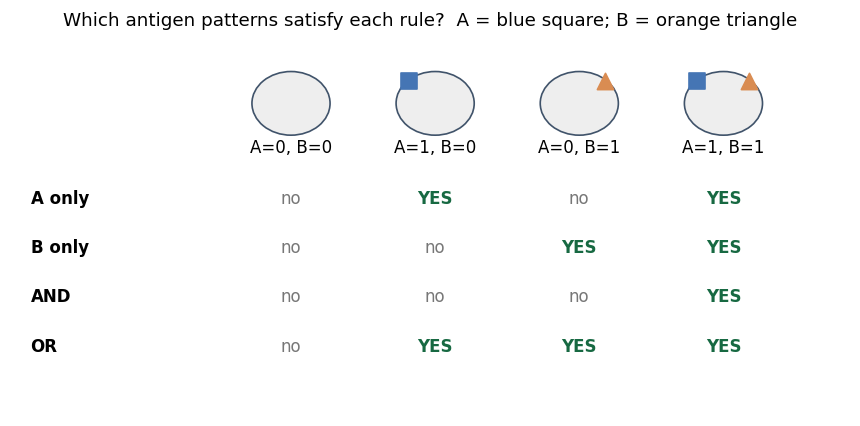

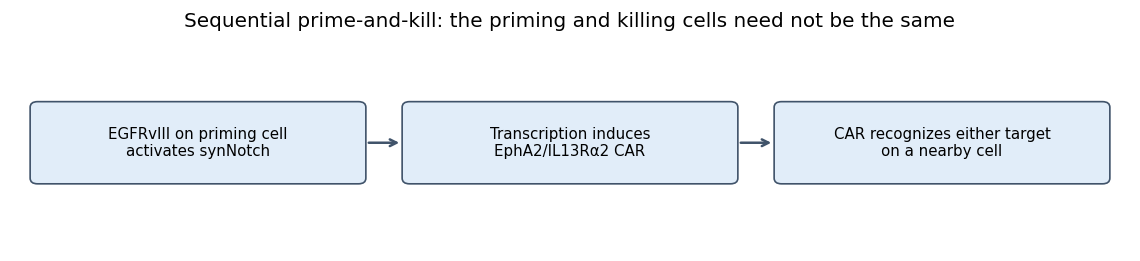

In [ ]:
# Visual examples of the same-cell recognition rules (schematic, not data).
fig, ax = plt.subplots(figsize=(9,4.1)); ax.axis('off'); ax.set(xlim=(0,9),ylim=(0,5))
for j,(a,b) in enumerate([(0,0),(1,0),(0,1),(1,1)]):
    x=3+j*1.55
    ax.add_patch(plt.Circle((x,4.1),.42,fc='#eeeeee',ec='#40536a'))
    if a: ax.scatter(x-.28,4.4,marker='s',s=85,c='#4575b4')
    if b: ax.scatter(x+.28,4.4,marker='^',s=95,c='#d98c52')
    ax.text(x,3.45,f'A={a}, B={b}',ha='center',fontsize=10)
    for i,yes in enumerate([a,b,a and b,a or b]):
        ax.text(x,2.85-i*.65,'YES' if yes else 'no',ha='center',va='center',color='#176942' if yes else '#777777',weight='bold' if yes else 'normal')
for i,label in enumerate(['A only','B only','AND','OR']): ax.text(.2,2.85-i*.65,label,va='center',weight='bold')
ax.set_title('Which antigen patterns satisfy each rule?  A = blue square; B = orange triangle',fontsize=11)
plt.show()
fig,ax=plt.subplots(figsize=(12,2.3)); ax.axis('off'); ax.set(xlim=(0,12),ylim=(0,3))
for x,txt in [(2,'EGFRvIII on priming cell\nactivates synNotch'),(6,'Transcription induces\nEphA2/IL13Rα2 CAR'),(10,'CAR recognizes either target\non a nearby cell')]: node(ax,x,1.5,txt,'#e1edf9',w=3.45,h=1)
arrow(ax,3.8,1.5,4.2,1.5); arrow(ax,7.8,1.5,8.2,1.5)
ax.set_title('Sequential prime-and-kill: the priming and killing cells need not be the same')
plt.show()

## 2. Data and setup
I use the Smart-seq2 expression matrix from Neftel et al. (2019), [GSE131928](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE131928), GSM3828672, together with the authors’ [SCP393](https://singlecell.broadinstitute.org/single_cell/study/SCP393) metadata file `IDHwt.GBM.Metadata.SS2.txt`. The metadata provides sample identifiers and cell assignments, allowing me to distinguish malignant cells from macrophages, oligodendrocytes and T cells. These nonmalignant cells come from tumor samples, not a comprehensive healthy-tissue atlas.

To reproduce in Colab, upload the metadata and either the original TAR archive or `gbm_target_expression.csv` (the four extracted genes). Both data files should be in the notebook's working directory. The deposited values are used as supplied; no additional normalization is applied. Thresholds are on the deposited expression scale, not calibrated surface protein concentrations.

In [ ]:
from pathlib import Path
import gzip, tarfile, io
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sys

print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| numpy:', np.__version__)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
output = Path('gbm_results')
output.mkdir(exist_ok=True)
genes = ['EPHA2', 'IL13RA2', 'EGFR', 'ERBB2']
archive = Path('GSE131928_RAW.tar')
small_file = Path('gbm_target_expression.csv')


Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6


## 3. Extract and check the data
The original matrix has genes in rows and cells in columns. Since this project focuses on four genes, I read only the relevant rows into memory. This avoids creating a large dense matrix unnecessarily. The resulting table has one cell per row.

In [ ]:
def read_targets(archive, genes):
    with tarfile.open(archive) as tar:
        members = [m for m in tar.getmembers() if m.name.endswith('GSM3828672_Smartseq2_GBM_IDHwt_processed_TPM.tsv.gz')]
        if len(members) != 1:
            raise ValueError('Expected exactly one Smart-seq2 expression matrix')
        with gzip.open(tar.extractfile(members[0]), 'rt') as f:
            header = next(f)
            selected = [line for line in f if line.split('\t', 1)[0] in genes]
    return pd.read_csv(io.StringIO(header + ''.join(selected)), sep='\t', index_col=0).T

if small_file.exists():
    expr = pd.read_csv(small_file, index_col=0)
elif archive.exists():
    expr = read_targets(archive, genes)
    expr.to_csv(small_file)
else:
    raise FileNotFoundError('Upload the original TAR or gbm_target_expression.csv to this directory.')
expr = expr[genes].apply(pd.to_numeric, errors='raise')
assert expr.index.is_unique and expr.columns.is_unique
assert np.isfinite(expr.to_numpy()).all() and (expr >= 0).all().all()
expr.index.name = 'cell_id'
metadata = pd.read_csv('IDHwt.GBM.Metadata.SS2.txt', sep='\t', skiprows=[1]).set_index('NAME', verify_integrity=True)
# The second line specifies column types, not a biological observation.
assert set(expr.index) == set(metadata.index), 'Cell IDs do not match exactly'
metadata = metadata.reindex(expr.index)
assert metadata['CellAssignment'].isin(['Malignant','Macrophage','Oligodendrocyte','T-cell']).all()
sample = metadata['Sample']
malignant = metadata['CellAssignment'].eq('Malignant')
group = malignant.map({True:'Malignant', False:'Nonmalignant'})
print(f'{len(expr):,} matched cells; {sample.nunique()} sample IDs')
display(metadata.CellAssignment.value_counts().to_frame('Cells'))
display(expr.head())


7,930 matched cells; 28 sample IDs


,Cells
CellAssignment,
Malignant,6863
Macrophage,754
Oligodendrocyte,219
T-cell,94


,EPHA2,IL13RA2,EGFR,ERBB2
cell_id,,,,
MGH101-P1-A04,0.000000,0.0,0.000000,0.0
MGH101-P1-A05,0.000000,0.0,0.000000,0.0
MGH101-P1-A07,3.101818,0.0,0.000000,0.0
MGH101-P1-A09,0.000000,0.0,0.041243,0.0
MGH101-P1-A10,0.000000,0.0,0.000000,0.0


## 4. Antigen detection and heterogeneity
I define detectable RNA as a deposited value greater than zero. I first compare the four targets across malignant cells within each sample, then examine detection in each annotated cell type. This helps separate tumor heterogeneity from differences in sample composition.

**How to read Figure 1:** Each column is a sample; each row is a gene. Color represents the percentage of malignant cells with detectable RNA, not average expression.

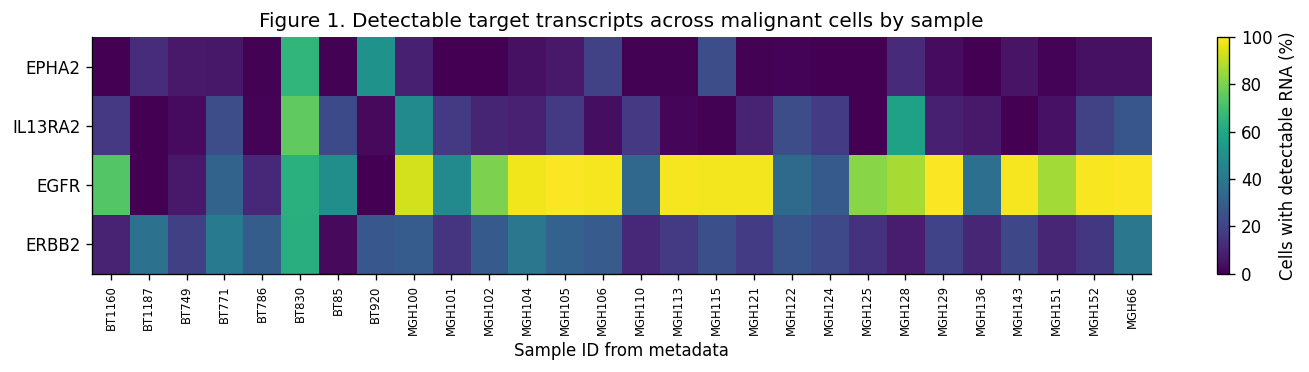

,EPHA2,IL13RA2,EGFR,ERBB2
CellAssignment,,,,
Macrophage,5.84,0.00,2.65,3.45
Malignant,7.90,16.06,67.01,24.09
Oligodendrocyte,0.00,0.46,4.11,3.65
T-cell,1.06,0.00,0.00,2.13


In [ ]:
threshold = 0.0
positive = expr.gt(threshold)
by_sample = positive.loc[malignant].groupby(sample[malignant]).mean() * 100
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(by_sample.T, aspect='auto', vmin=0, vmax=100, cmap='viridis')
ax.set_xticks(range(len(by_sample)), by_sample.index, rotation=90, fontsize=7)
ax.set_yticks(range(len(genes)), genes)
ax.set_xlabel('Sample ID from metadata')
ax.set_title('Figure 1. Detectable target transcripts across malignant cells by sample')
fig.colorbar(im, ax=ax, label='Cells with detectable RNA (%)')
fig.tight_layout(); fig.savefig(output/'figure1_detection.png', dpi=250); plt.show()
display((positive.groupby(metadata.CellAssignment).mean()*100).round(2))


## 5. EPHA2 and IL13RA2 co-expression
A cell can express neither transcript, only one, or both. The distribution among these four categories determines how much an OR gate adds beyond a single target. An AND gate, in contrast, selects only the double-positive category.

**How to read Figure 2:** The two single-positive categories explain the extra coverage from OR; the double-positive category is the strict AND result.

,cells,percent
Neither,5386,78.48
EPHA2 only,375,5.46
IL13RA2 only,935,13.62
Both,167,2.43


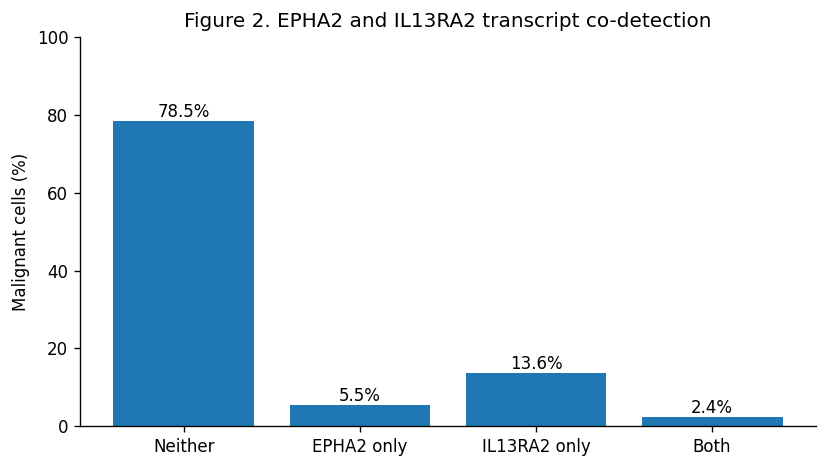

In [ ]:
A, B = positive['EPHA2'], positive['IL13RA2']
classes = pd.DataFrame({'Neither': ~A & ~B, 'EPHA2 only': A & ~B,
                        'IL13RA2 only': ~A & B, 'Both': A & B})
assert classes.sum(axis=1).eq(1).all()
counts = classes.loc[malignant].sum()
coexpression = pd.DataFrame({'cells': counts, 'percent': counts/malignant.sum()*100})
display(coexpression.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(coexpression.index, coexpression['percent'])
ax.set_ylabel('Malignant cells (%)'); ax.set_ylim(0, 100)
ax.set_title('Figure 2. EPHA2 and IL13RA2 transcript co-detection')
for i, v in enumerate(coexpression['percent']): ax.text(i, v+1, f'{v:.1f}%', ha='center')
fig.tight_layout(); fig.savefig(output/'figure2_coexpression.png', dpi=250); plt.show()


## 6. Implementing hypothetical CAR targeting rules
For each cell, a Boolean rule returns True if the transcript condition is satisfied. The coverage proxy is the fraction of cells satisfying that rule. The AND rule here requires simultaneous co-detection in one cell and does not represent the sequential, spatial priming behavior of a synNotch circuit.

**How to read Figure 3:** Each dot is one sample, and the box summarizes the distribution across samples. The pooled percentage weights samples by cell count.

,pooled_percent,sample_median,sample_min,sample_max
EPHA2 single,7.90,3.77,0.0,65.91
IL13RA2 single,16.06,9.89,0.0,75.45
AND,2.43,0.00,0.0,51.82
OR,21.52,17.13,0.3,89.55


/tmp/ipykernel_533/1087464687.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([sample_coverage[k] for k in rules], labels=list(rules), showfliers=False)


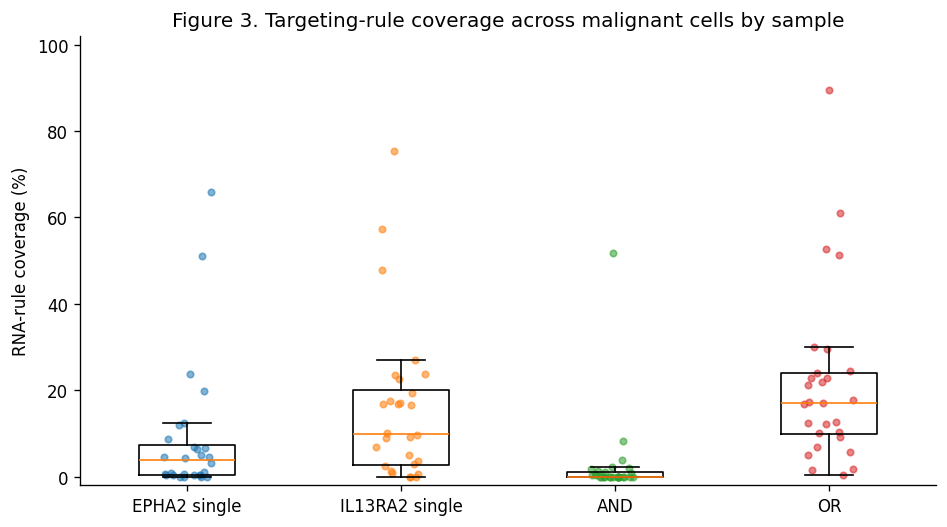

OR improvement over strongest single target: 5.46 percentage points


In [ ]:
def targeting_rules(expression, a, b, threshold=0):
    a_pos, b_pos = expression[a].gt(threshold), expression[b].gt(threshold)
    return pd.DataFrame({'EPHA2 single': a_pos, 'IL13RA2 single': b_pos,
                         'AND': a_pos & b_pos, 'OR': a_pos | b_pos}) if (a,b)==('EPHA2','IL13RA2') else pd.DataFrame({a:a_pos,b:b_pos,'AND':a_pos & b_pos,'OR':a_pos | b_pos})

# Check all four possible input combinations before using biological data.
test = pd.DataFrame({'EPHA2':[0,1,0,1], 'IL13RA2':[0,0,1,1]})
assert targeting_rules(test,'EPHA2','IL13RA2')['AND'].tolist() == [False,False,False,True]
assert targeting_rules(test,'EPHA2','IL13RA2')['OR'].tolist() == [False,True,True,True]
rules = targeting_rules(expr,'EPHA2','IL13RA2')
coverage = rules.loc[malignant].mean()*100
sample_coverage = rules.loc[malignant].groupby(sample[malignant]).mean()*100
summary = pd.DataFrame({'pooled_percent':coverage,'sample_median':sample_coverage.median(),
                        'sample_min':sample_coverage.min(),'sample_max':sample_coverage.max()})
display(summary.round(2))
fig, ax = plt.subplots(figsize=(8,4.5))
ax.boxplot([sample_coverage[k] for k in rules], labels=list(rules), showfliers=False)
rng = np.random.default_rng(42)
for i,k in enumerate(rules,1):
    ax.scatter(i+rng.uniform(-.12,.12,len(sample_coverage)), sample_coverage[k], s=15, alpha=.55)
ax.set_ylabel('RNA-rule coverage (%)'); ax.set_ylim(-2,102)
ax.set_title('Figure 3. Targeting-rule coverage across malignant cells by sample')
fig.tight_layout(); fig.savefig(output/'figure3_rules.png',dpi=250); plt.show()
print(f'OR improvement over strongest single target: {coverage.OR-max(coverage.iloc[:2]):.2f} percentage points')


## 7. Sensitivity analysis and exploratory target pairs
The zero threshold may be overly permissive for a receptor that requires sufficient surface antigen density. I repeat the calculation with higher cutoffs on the deposited expression scale (0, 0.5, 1, 2). These are illustrative, not calibrated CAR activation thresholds. I also compare all six pairs of the four prespecified targets to see whether the focal pair is unusual; this is exploratory and does not establish the best therapeutic targets.

**How to read Figure 4:** Each line follows the same rule as the cutoff increases. The cutoff is a computational assumption, not a measured receptor activation threshold.

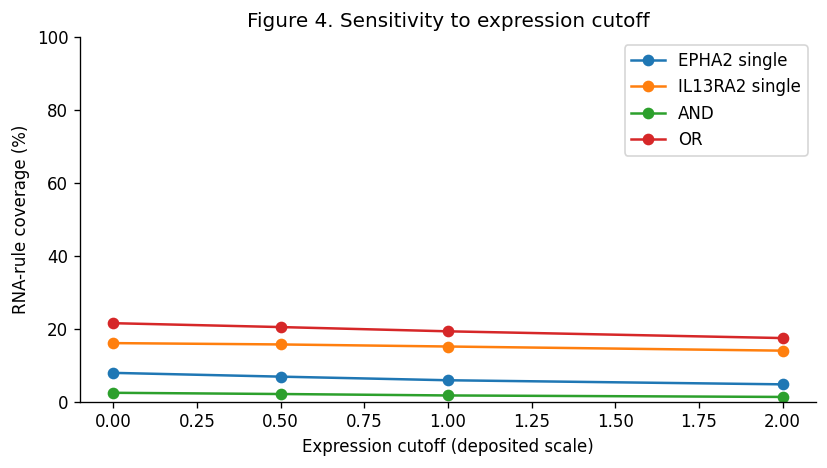

,EPHA2 single,IL13RA2 single,AND,OR
0.0,7.90,16.06,2.43,21.52
0.5,6.86,15.69,2.10,20.46
1.0,5.87,15.12,1.70,19.29
2.0,4.75,13.99,1.30,17.44


,pair,AND (%),OR (%),Nonmalignant OR (%),Nonmalignant AND (%),OR gain (pp)
4,IL13RA2 + ERBB2,5.07,35.07,3.47,0.00,10.99
5,EGFR + ERBB2,16.87,74.22,6.09,0.00,7.21
0,EPHA2 + IL13RA2,2.43,21.52,4.31,0.00,5.46
2,EPHA2 + ERBB2,3.02,28.97,7.40,0.19,4.88
3,IL13RA2 + EGFR,11.73,71.34,2.81,0.00,4.33
1,EPHA2 + EGFR,4.50,70.41,6.37,0.56,3.40


In [ ]:
thresholds = [0, .5, 1, 2]
sensitivity = pd.DataFrame({t:targeting_rules(expr.loc[malignant],'EPHA2','IL13RA2',t).mean()*100 for t in thresholds}).T
fig, ax = plt.subplots(figsize=(7,4))
for k in sensitivity: ax.plot(sensitivity.index,sensitivity[k],marker='o',label=k)
ax.set(xlabel='Expression cutoff (deposited scale)',ylabel='RNA-rule coverage (%)',title='Figure 4. Sensitivity to expression cutoff',ylim=(0,100))
ax.legend(); fig.tight_layout(); fig.savefig(output/'figure4_thresholds.png',dpi=250); plt.show()
display(sensitivity.round(2))
rows=[]
for a,b in combinations(genes,2):
    r=targeting_rules(expr.loc[malignant],a,b).mean()*100
    non=targeting_rules(expr.loc[~malignant],a,b).mean()*100
    rows.append({'pair':f'{a} + {b}','AND (%)':r['AND'],'OR (%)':r['OR'], 'Nonmalignant OR (%)':non['OR'], 'Nonmalignant AND (%)':non['AND'], 'OR gain (pp)':r['OR']-max(r.iloc[:2])})
pairs=pd.DataFrame(rows).sort_values('OR gain (pp)',ascending=False)
display(pairs.round(2))


## 8. Comparing malignant and nonmalignant cells
The original cell annotations let me quantify how often each rule is satisfied in malignant cells versus other cells from the same tumor samples. This comparison is a proxy for selectivity, not clinical toxicity. I also report individual nonmalignant cell types because pooling them can hide differences in expression.

**How to read Figure 5:** Compare the two bars for each design. Lower nonmalignant recognition is desirable as a screening proxy, but does not establish safety.

,EPHA2 single,IL13RA2 single,AND,OR
CellAssignment,,,,
Malignant,7.90,16.06,2.43,21.52
Nonmalignant,4.22,0.09,0.00,4.31


,EPHA2 single,IL13RA2 single,AND,OR
CellAssignment,,,,
Macrophage,5.84,0.00,0.00,5.84
Malignant,7.90,16.06,2.43,21.52
Oligodendrocyte,0.00,0.46,0.00,0.46
T-cell,1.06,0.00,0.00,1.06


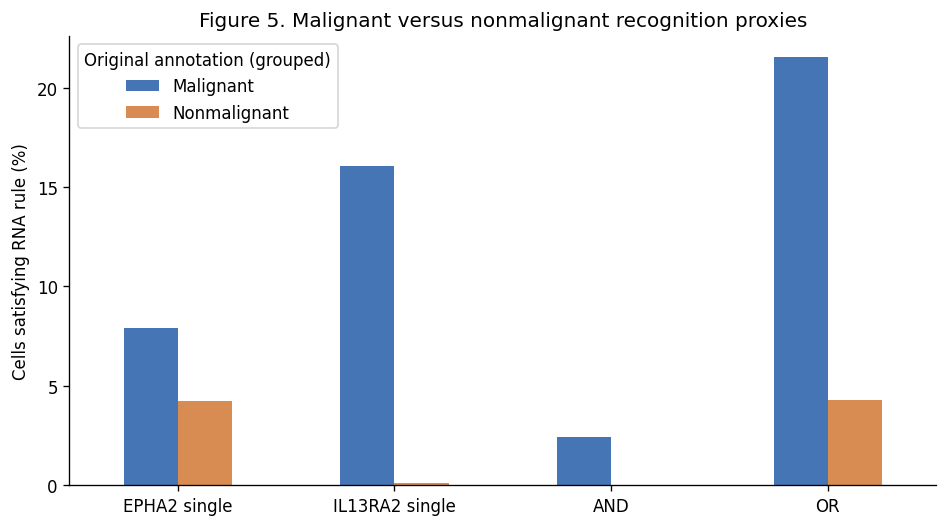

EPHA2 single  IL13RA2 single    AND     OR
Sample CellAssignment                                            
BT1160 Malignant               0.00           16.72   0.00  16.72
BT1187 Malignant              12.50            0.00   0.00  12.50
       Nonmalignant            2.37            0.00   0.00   2.37
BT749  Malignant               6.67            2.86   0.32   9.21
       Nonmalignant            0.00            0.00   0.00   0.00
BT771  Malignant               6.40           23.78   0.61  29.57
       Nonmalignant            0.00            0.00   0.00   0.00
BT786  Malignant               0.48            0.96   0.00   1.44
       Nonmalignant            0.00            0.00   0.00   0.00
BT830  Malignant              65.91           75.45  51.82  89.55
BT85   Malignant               0.41           22.54   0.00  22.95
       Nonmalignant            0.00            0.00   0.00   0.00
BT920  Malignant              51.04            2.43   2.08  51.39
       Nonmalignant            0.00            0.00   0.00   0.00
MGH100 Malignant               8.61           47.85   3.83  52.63
MGH101 Malignant               0.00           16.99   0.00  16.99
       Nonmalignant            4.26            0.00   0.00   4.26
MGH102 Malignant               0.00           10.19   0.00  10.19
       Nonmalignant           13.21            0.00   0.00  13.21
MGH104 Malignant               4.51            9.30   1.13  12.68
MGH105 Malignant               6.82           16.92   1.77  21.97
       Nonmalignant            5.04            0.00   0.00   5.04
MGH106 Malignant              19.85            3.68   2.21  21.32
       Nonmalignant            0.00            0.00   0.00   0.00
MGH110 Malignant               0.66           16.61   0.00  17.28
       Nonmalignant            0.00            1.72   0.00   1.72
MGH113 Malignant               0.47            1.40   0.00   1.87
       Nonmalignant            2.17            0.00   0.00   2.17
MGH115 Malignant              23.75            0.62   0.00  24.38
       Nonmalignant           40.00            0.00   0.00  40.00
MGH121 Malignant               0.68            9.59   0.00  10.27
       Nonmalignant            0.00            0.00   0.00   0.00
MGH122 Malignant               1.00           23.50   0.50  24.00
       Nonmalignant            1.37            0.00   0.00   1.37
MGH124 Malignant               0.31           17.43   0.00  17.74
       Nonmalignant           13.95            0.00   0.00  13.95
MGH125 Malignant               0.30            0.00   0.00   0.30
       Nonmalignant            2.99            0.00   0.00   2.99
MGH128 Malignant              11.95           57.23   8.18  61.01
       Nonmalignant            0.00            0.00   0.00   0.00
MGH129 Malignant               3.16            8.95   0.00  12.11
       Nonmalignant            0.00            0.00   0.00   0.00
MGH136 Malignant               0.00            6.99   0.00   6.99
       Nonmalignant            0.00            0.00   0.00   0.00
MGH143 Malignant               5.13            0.00   0.00   5.13
       Nonmalignant            0.00            0.00   0.00   0.00
MGH151 Malignant               0.83            4.96   0.00   5.79
       Nonmalignant            0.00            0.00   0.00   0.00
MGH152 Malignant               4.39           19.30   0.88  22.81
       Nonmalignant            0.00            0.00   0.00   0.00
MGH66  Malignant               4.60           26.90   1.38  30.11
       Nonmalignant            0.00            0.00   0.00   0.00

In [ ]:
group_coverage = rules.groupby(group).mean()*100
celltype_coverage = rules.groupby(metadata.CellAssignment).mean()*100
display(group_coverage.round(2))
display(celltype_coverage.round(2))
fig, ax = plt.subplots(figsize=(8,4.5))
group_coverage.T.plot.bar(ax=ax, rot=0, color=['#4575b4','#d98c52'])
ax.set(ylabel='Cells satisfying RNA rule (%)', title='Figure 5. Malignant versus nonmalignant recognition proxies')
ax.legend(title='Original annotation (grouped)'); fig.tight_layout(); fig.savefig(output/'figure5_selectivity.png',dpi=250); plt.show()
# Use matched sample IDs for a descriptive comparison where both groups are represented.
matched = rules.groupby([sample,group]).mean()*100
matched.to_csv(output/'sample_group_coverage.csv')
display(matched.round(2))


## 9. Results and interpretation
The following summary is generated directly from the data, so the reported values remain consistent if the analysis is rerun.

In [ ]:
print(f'Of {malignant.sum():,} malignant cells, {coverage.iloc[0]:.2f}% had detectable EPHA2 and {coverage.iloc[1]:.2f}% had detectable IL13RA2.')
print(f'Malignant OR: {coverage.OR:.2f}%; AND: {coverage.AND:.2f}%.')
print(f'Malignant OR gain over better single target: {coverage.OR-max(coverage.iloc[:2]):.2f} percentage points.')
print(f'Nonmalignant OR: {group_coverage.loc["Nonmalignant","OR"]:.2f}%; AND: {group_coverage.loc["Nonmalignant","AND"]:.2f}%.')
print(f'Malignant sample OR range: {sample_coverage.OR.min():.2f}–{sample_coverage.OR.max():.2f}% (median {sample_coverage.OR.median():.2f}%).')
print(f'At cutoff 2, malignant OR coverage was {sensitivity.loc[2,"OR"]:.2f}%.')


Of 6,863 malignant cells, 7.90% had detectable EPHA2 and 16.06% had detectable IL13RA2.
Malignant OR: 21.52%; AND: 2.43%.
Malignant OR gain over better single target: 5.46 percentage points.
Nonmalignant OR: 4.31%; AND: 0.00%.
Malignant sample OR range: 0.30–89.55% (median 17.13%).
At cutoff 2, malignant OR coverage was 17.44%.


## 10. Discussion
The useful part of this comparison is not that OR covers more cells than AND, since this follows directly from Boolean logic. What matters is how much additional coverage the second target contributes and how that gain varies across samples. Cells that satisfy only one of the two conditions illustrate why multi-target recognition could help address antigen heterogeneity. Conversely, a strict AND gate excludes those cells by design. The sensitivity analysis also makes clear that a detection-based estimate depends on the expression cutoff.

These findings relate to the EphA2/IL13Rα2 killing module in Choe et al. (2021), but the complete circuit requires prior priming by EGFRvIII. The analysis cannot establish the presence of EGFRvIII from gene-level EGFR expression. It also does not capture distances between cells, persistence of induced CAR expression, receptor signaling strength or T-cell exhaustion. Therefore it is a simplified analysis of candidate killing targets, not a prediction of the full synNotch circuit.

Among the 6,863 malignant cells, the OR rule covered 21.52% compared with 16.06% for IL13RA2 alone and 7.90% for EPHA2 alone. The AND rule covered only 2.43%. This suggests that the two targets identify largely distinct subsets of malignant cells, but the detected transcripts still leave most malignant cells outside the OR rule. In the sampled nonmalignant cells, no cell satisfied the strict AND rule at the zero threshold. That is not proof of safety: some macrophages, oligodendrocytes and T cells satisfied single-target or OR rules, and this dataset does not represent healthy tissues throughout the body.

RNA detection is not the same as surface protein abundance, and single-cell RNA sequencing is affected by nondetection. The sample-level summaries are descriptive; pooling cells gives greater weight to larger samples. I avoid treating individual cells as independent patient replicates or reporting misleading significance tests. A next step would be to validate the candidate proteins with flow cytometry or immunostaining, examine independent healthy-tissue data and test actual CAR activation and cytotoxicity experimentally.

## 11. Conclusion
This analysis illustrates how single-cell expression data can inform the design of programmable immune-cell recognition rules. It quantifies the coverage trade-off among simple single-target, AND and OR designs, while emphasizing that transcriptional coverage is only one factor in selecting an effective and safe immunotherapy.

In [ ]:
summary.to_csv(output/'coverage_summary.csv')
sample_coverage.to_csv(output/'sample_coverage.csv')
coexpression.to_csv(output/'coexpression.csv')
sensitivity.to_csv(output/'threshold_sensitivity.csv')
pairs.to_csv(output/'exploratory_pairs.csv',index=False)
by_sample.to_csv(output/'sample_detection.csv')
print('Saved figures and tables to',output.resolve())
group_coverage.to_csv(output/'group_coverage.csv')
celltype_coverage.to_csv(output/'celltype_coverage.csv')
expr.join(metadata).to_csv(output/'annotated_expression.csv')

Saved figures and tables to /content/gbm_results


## References
1. Neftel, C., et al. (2019). An integrative model of cellular states, plasticity, and genetics for glioblastoma. *Cell*, 178, 835–849.e21. https://doi.org/10.1016/j.cell.2019.06.024
2. Choe, J. H., et al. (2021). SynNotch-CAR T cells overcome challenges of specificity, heterogeneity, and persistence in treating glioblastoma. *Science Translational Medicine*, 13, eabe7378. https://doi.org/10.1126/scitranslmed.abe7378
3. Roybal, K. T., et al. (2016). Precision tumor recognition by T cells with combinatorial antigen-sensing circuits. *Cell*, 164, 770–779. https://doi.org/10.1016/j.cell.2016.01.011ducible